In [1]:
import wandb
api = wandb.Api()

# run is specified by <entity>/<project>/<run id>

exp = "am98lznu"

run = api.run(f"ramithx1/Differentiable-Trees/{exp}")

# save the metrics for the run to a csv file
metrics_dataframe = run.history()
metrics_dataframe.to_csv("metrics.csv")

In [1]:
import os

In [3]:
metrics_dataframe['tree matrix']

0      {'sha256': 'c4986bd88b67918f37fde337a312fa158b...
1      {'_type': 'plotly-file', 'path': 'media/plotly...
2      {'size': 3625338, '_type': 'plotly-file', 'pat...
3      {'path': 'media/plotly/tree matrix_27_01fae7da...
4      {'path': 'media/plotly/tree matrix_42_3b06d135...
                             ...                        
493    {'_type': 'plotly-file', 'path': 'media/plotly...
494    {'sha256': 'daa0bb21af6a28fb8bedbf260ec2f1d8a4...
495    {'_type': 'plotly-file', 'path': 'media/plotly...
496    {'_type': 'plotly-file', 'path': 'media/plotly...
497    {'_type': 'plotly-file', 'path': 'media/plotly...
Name: tree matrix, Length: 498, dtype: object

In [4]:
metrics_dataframe['tree matrix'][1]

{'_type': 'plotly-file',
 'path': 'media/plotly/tree matrix_12_f6a949621aa309090f25.plotly.json',
 'sha256': 'f6a949621aa309090f25ca7cb95b4c991c096d0e0cd5c3c247a2840f1c6837f2',
 'size': 3612056}

In [9]:
type(run.files())

wandb.apis.public.Files

In [11]:
k = list(filter(lambda x: 'plotly' in str(x) and 'tree matrix' in str(x), run.files()))

In [ ]:

for k in run.files():

    if('plotly' in str(k) and 'tree matrix' in str(k)):
        print(str(k))
        k.download()
        break

In [ ]:
image_folder = '/n/home12/ramith/solab/differentiable-trees/viz-tools/media/plotly/'

In [3]:
image_folder = '/n/holyscratch01/wadduwage_lab/ramith/differentiable-trees/wandb/run-20230203_202656-am98lznu/files/media/plotly/'

In [2]:
image_folder = '/n/holyscratch01/wadduwage_lab/ramith/differentiable-trees/wandb/run-20230204_004852-9b8mfsi4/files/media/plotly/'

In [48]:
image_folder = "/n/holyscratch01/wadduwage_lab/ramith/differentiable-trees/wandb/run-20230204_005230-2hyzwuxr/files/media/plotly/"

In [49]:
images = [img for img in os.listdir(image_folder) if 'plotly' in img and 'tree matrix' in img ]


In [50]:
images.sort(key=lambda x: int(x.split('_')[1]))

In [51]:
images[0]

'tree matrix_1_f17f0d010c3937424ad8.plotly.json'

In [52]:
import numpy as np
import json
import matplotlib.pyplot as plt

In [55]:
images[1000]

'tree matrix_1001_ca0f64135634a0f5cfc7.plotly.json'

In [65]:
f = open(image_folder + images[2500])
data = json.load(f)

arr = np.array(data['data'][0]['z'])

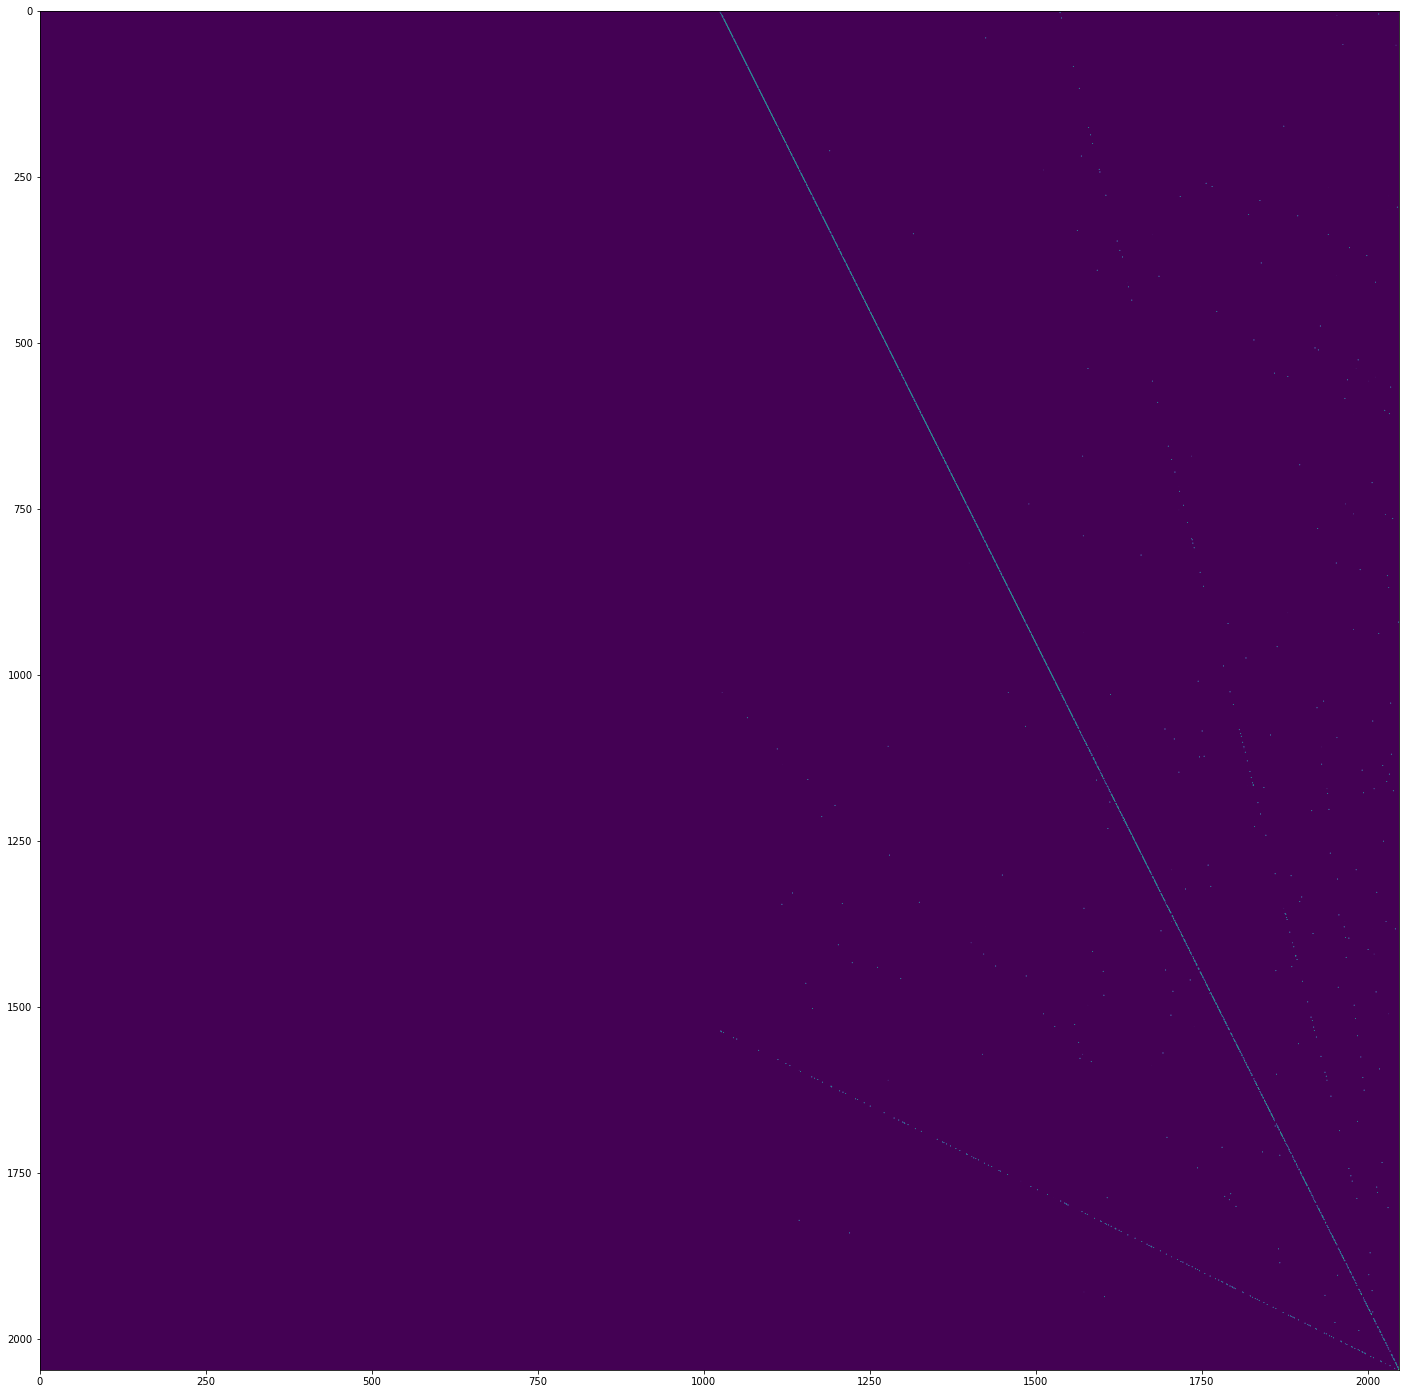

In [66]:
plt.figure(figsize=(25,25))
plt.imshow(arr)


In [68]:
import cv2

In [69]:
frame = arr
height, width = frame.shape
video_name = "experiment-2hyzwuxr.mp4"

print(height, width)

2047 2047


In [33]:
import scipy.misc
from PIL import Image

In [ ]:
fourcc = cv2.VideoWriter_fourcc(*'MPEG')
video = cv2.VideoWriter(video_name,fourcc, 30.0, (1920,1920))

i = 0
it = 0
while(i<2500):
    f = open(image_folder + images[i])
    data = json.load(f)
    
    np_array = np.array(data['data'][0]['z'])*255.0
    
    image1copy = np.uint8(np_array)

    grayscale_image  = cv2.cvtColor(image1copy, cv2.COLOR_GRAY2RGB)
    grayscale_image = cv2.resize(grayscale_image,(1920,1920),fx=0,fy=0, interpolation =  cv2.INTER_NEAREST)
    
    
    upper = 0.9*255
    im_color = cv2.normalize(grayscale_image, None, 0, upper, cv2.NORM_MINMAX)
    im_color = cv2.applyColorMap(im_color, cv2.COLORMAP_JET)


    
    if(it<70):
        if(it%7==0):
            i+=1
    elif(it<250):
        if(it%20==0):
            i+=1
    else:
        i+=1
    
    it+=1
    
    #plt.imshow(np_array)
    video.write(im_color)

cv2.destroyAllWindows()
video.release()

OpenCV: FFMPEG: tag 0x4745504d/'MPEG' is not supported with codec id 2 and format 'mp4 / MP4 (MPEG-4 Part 14)'
OpenCV: FFMPEG: fallback to use tag 0x7634706d/'mp4v'


In [35]:
print(i)

1000


In [123]:
def give_n_image(x):
    f = open(image_folder + images[x])
    data = json.load(f)
    
    np_array = np.array(data['data'][0]['z'])
    
    return np_array


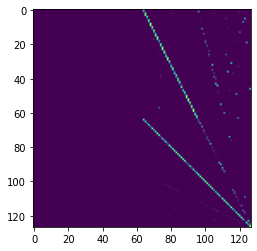

In [159]:
plt.imshow(give_n_image(60))